# 1. QQQ Daily RSI(2) Mean Reversion - Hypothesis Definition & Baseline Backtest

This notebook formulates the quantitative hypothesis and establishes the baseline backtest for the **Alphaca RSI(2) Mean Reversion** strategy on **Invesco QQQ Trust (QQQ)** daily bars.

### 1.1 Core Quantitative Hypothesis
The strategy exploits a structural property of equity index markets identified in our Exploratory Data Analysis:
- **Macro Trend Drift**: The Nasdaq-100 exhibits a persistent multi-decade upward drift (~10.9% CAGR since 1999).
- **Short-Term Micro Reversal**: Daily returns exhibit negative autocorrelation (Lag 1 ACF = -0.058) and a sub-diffusive Hurst exponent ($H = 0.48 < 0.50$).
- **The Core Premise**: When an asset in a macro bull market (`Close > SMA(between 190 and 250)`) experiences severe, sudden selling pressure (`RSI(2) < between 15 and 22`), institutional liquidity providers step in to absorb retail stop-losses and panics. The resulting bounce generates an asymmetric, high-probability mean-reverting edge over the subsequent 2 to 5 sessions.

### 1.2 Frozen Strategy Rules
| Rule Component | Specification |
| :--- | :--- |
| **Instrument** | Invesco QQQ Trust (`QQQ`), Daily bars (split/dividend adjusted) |
| **Trend Filter** | `Close[t-1] > SMA(between 190 and 250)[t-1]` (evaluated at day $t-1$ close) |
| **Entry Trigger** | `RSI(2)[t-1] < between 15 and 22` (Wilder smoothing, evaluated at day $t-1$ close) |
| **Execution** | Buy at **OPEN** of day $t$ with slippage cost: `Entry = Open[t] * (1 + 0.0005)` |
| **Exit Trigger** | Two consecutive green candles: `Close[t-1] > Open[t-1]` AND `Close[t-2] > Open[t-2]` |
| **Exit Execution** | Sell at **OPEN** of day $t$ with slippage cost: `Exit = Open[t] * (1 - 0.0005)` |
| **Direction** | Long only, no price stop loss |
| **Trading Costs** | 5 bps per side (0.05% per side = 10 bps round-trip), zero commission |
| **Position Sizing** | (a) **Capital Sizing**: 100% equity per trade<br>(b) **ATR Risk Sizing**: 1% risk per trade with 2x ATR(14) stop, capped at 100% |

### 1.3 Provenance & Adaptation
- **Academic / Practitioner Origin**: Developed by Larry Connors & Cesar Alvarez (*Short Term Trading Strategies That Work*, 2008).
- **Alphaca Refinement**: Alphaca adapted the exit logic from a fixed MA(5) cross to an agile two-consecutive-green-candles price-action exit, increasing trade velocity and reducing overnight drawdown exposure.

In [1]:
# Strategy parameters
SMA_LEN =230
RSI_THR = 20.0

### 01-4 Strategy Parameters

In [2]:
# Parameters cell (tag: "parameters"). papermill overrides this value.
VARIANT = "v1_qqq"

## 2. IMPORTS AND CONFIG

In [ ]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ---- Paths ----
utils_path  = os.path.abspath('../../../utils')
engine_path = os.path.abspath('..')
engine_dir  = os.path.abspath('../rsi2_engine')

for p in (utils_path, engine_path, engine_dir):
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import compute_metrics, plot_equity_curve
from metrics import sharpe_ratio, max_drawdown
import rsi2_engine as eng
import variant_config
from variant_config import load_variant, save_json

# variants/ está al mismo nivel que notebooks/, no en utils/
variant_config.EDGE_DIR = Path('..').resolve()
assert (variant_config.EDGE_DIR / "variants").is_dir(), \
    f"No existe {variant_config.EDGE_DIR / 'variants'}"

# ---- Variant config: single source of truth ----
cfg        = load_variant(VARIANT)
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
SMA_LEN    = cfg["params"]["sma_len"]
RSI_THR    = cfg["params"]["rsi_thr"]
EXIT_MODE  = cfg["params"]["exit_mode"]
SLIP_BPS   = cfg["params"]["slip_bps_per_side"]
SLIP       = SLIP_BPS / 10_000

print("Imports complete.")
print(f"Loaded utils from: {utils_path}")
print(f"Loaded rsi2_engine from: {eng.__file__}")
print(f"Variant: {cfg['id']} | {TICKER} | RSI(2) < {RSI_THR:g} | SMA({SMA_LEN}) | exit={EXIT_MODE} | {SLIP_BPS:g} bps/side")
print(f"Run folder: {RUN_DIR}")

Imports complete.
Loaded utils from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/utils
Loaded rsi2_engine from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/RSI2/rsi2_engine.py
Variant: RSI2.v1 | QQQ | RSI(2) < 20 | SMA(230) | exit=2green | 5 bps/side
Run folder: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/RSI2/runs/v1_qqq


## 3. LOAD DATA AND IN-SAMPLE / OUT-OF-SAMPLE SPLIT

In [4]:
# Execution rules and split date come from the variant config (previous cell)

# Download daily data from Yahoo Finance
df_raw = eng.load_data(TICKER, start=DATA_START)
df = eng.prepare(df_raw, sma_len=SMA_LEN)

n_is = int((df.index < OOS_START).sum())
df_is = df.iloc[:n_is].copy()
df_oos = df.iloc[n_is:].copy()
assert len(df_is) > 0 and len(df_oos) > 0, "Check split.oos_start against the history of this ticker."
oos_start = df_oos.index[0]

print("=" * 70)
print("DATA INGESTION & DATASET SPLIT")
print("=" * 70)
print(f"Total Prepared Bars: {len(df):,} ({df.index.min().strftime('%Y-%m-%d')} to {df.index.max().strftime('%Y-%m-%d')})")
print(f"In-Sample (IS, {len(df_is)/len(df)*100:.1f}%): {len(df_is):,} bars ({df_is.index.min().strftime('%Y-%m-%d')} to {df_is.index.max().strftime('%Y-%m-%d')})")
print(f"Out-of-Sample (OOS, {len(df_oos)/len(df)*100:.1f}%): {len(df_oos):,} bars ({df_oos.index.min().strftime('%Y-%m-%d')} to {df_oos.index.max().strftime('%Y-%m-%d')})")
print("=" * 70)

df.head()

DATA INGESTION & DATASET SPLIT
Total Prepared Bars: 6,713 (2000-02-03 to 2026-10-13)
In-Sample (IS, 69.8%): 4,689 bars (2000-02-03 to 2018-09-21)
Out-of-Sample (OOS, 30.2%): 2,024 bars (2018-09-24 to 2026-10-13)


,open,high,low,close,volume,sma,rsi2,green,ma5,atr14
time,,,,,,,,,,
2000-02-03,79.388299,81.334865,77.678478,81.229645,30579800,53.970438,93.398550,1,76.962981,3.508145
2000-02-04,81.650542,82.696163,80.992918,81.782066,26640000,54.139133,94.671006,1,78.841156,3.379223
2000-02-07,81.860950,83.018367,81.019192,82.913147,17761000,54.311830,97.021787,1,80.324754,3.280648
2000-02-08,83.649686,86.595838,83.649686,86.385399,21999400,54.504199,99.196903,1,82.097704,3.309366
2000-02-09,85.911906,86.023702,83.123583,83.334023,27258200,54.678041,43.438177,0,83.128856,3.305969


## 4. BASELINE BACKTEST WITH FROZEN RULES

PERFORMANCE SUMMARY (NET OF 5 BPS SLIPPAGE PER SIDE)


,Period,Sizing,Trades,Win Rate,Profit Factor,Expectancy,Total Return,Sharpe,Max Drawdown
0,In-Sample (2000-2018),100% Capital,237,65.4%,1.867,0.500%,208.3%,0.55,-21.79%
1,In-Sample (2000-2018),1% ATR Risk,237,65.4%,1.893,0.169%,48.3%,0.62,-6.69%
2,Out-of-Sample (2018-2026),100% Capital,123,78.0%,2.592,0.793%,156.3%,1.04,-12.14%
3,Out-of-Sample (2018-2026),1% ATR Risk,123,78.0%,2.414,0.246%,34.8%,0.98,-4.68%
4,Full Period (2000-2026),100% Capital,360,70.0%,2.094,0.601%,694.0%,0.70,-21.79%
5,Full Period (2000-2026),1% ATR Risk,360,70.0%,2.065,0.196%,100.4%,0.74,-6.69%


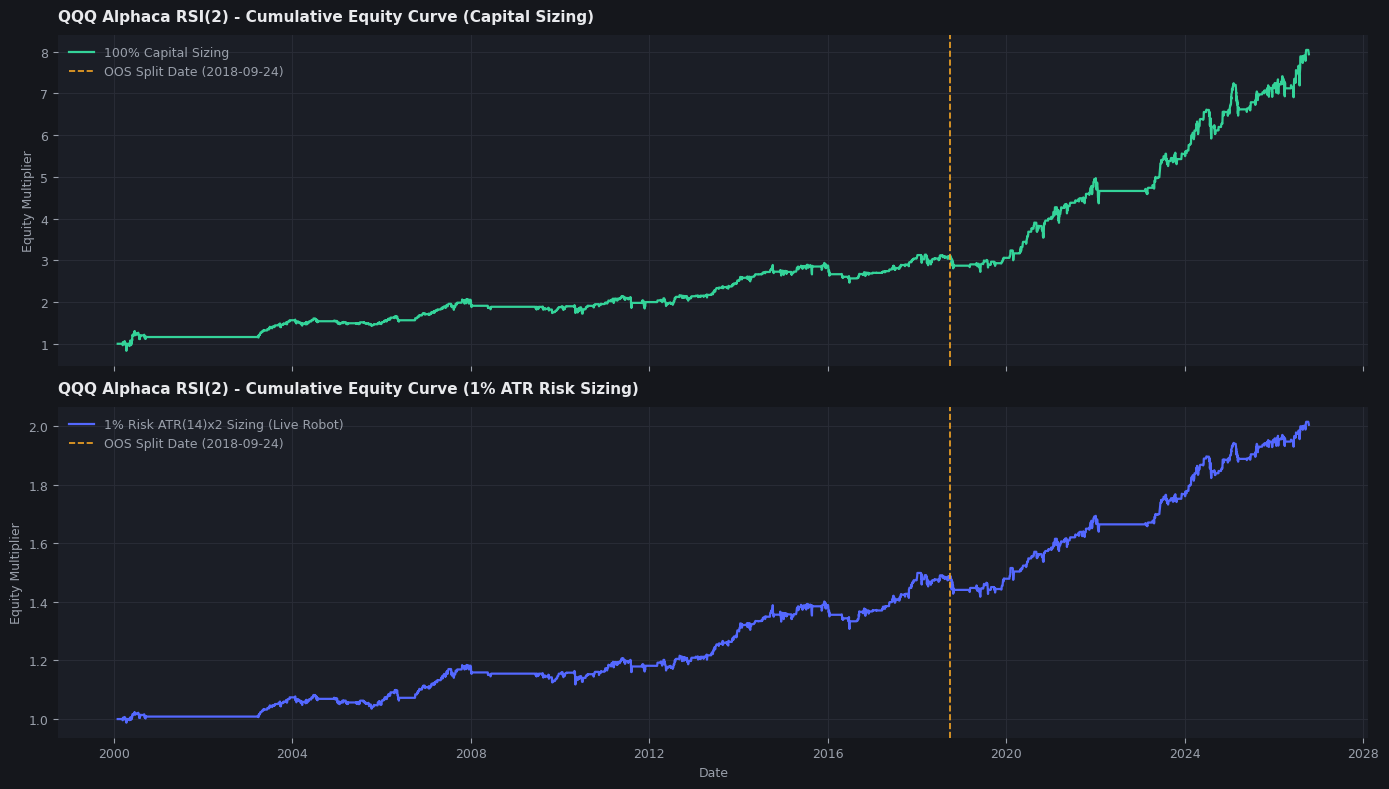

In [5]:
# Run backtest with frozen rules across IS, OOS, and Full Dataset
trades_is  = eng.run_rsi2_backtest(df_is,  rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)
trades_oos = eng.run_rsi2_backtest(df_oos, rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)
trades_all = eng.run_rsi2_backtest(df,     rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)

def format_perf_table(t_df, period_name, price_df):
    m_cap = compute_metrics(t_df, contract_multiplier=1.0, cost_per_trade=0.0)
    t_atr = t_df.assign(pnl=t_df['pnl_atr'], win=t_df['pnl_atr'] > 0)
    m_atr = compute_metrics(t_atr, contract_multiplier=1.0, cost_per_trade=0.0)

    ret_cap = eng.daily_returns(price_df, t_df, sizing="capital")
    ret_atr = eng.daily_returns(price_df, t_df, sizing="atr")

    eq_cap = (1.0 + ret_cap).cumprod()
    eq_atr = (1.0 + ret_atr).cumprod()

    return pd.DataFrame([
        {
            'Period': period_name,
            'Sizing': '100% Capital',
            'Trades': m_cap['num_trades'],
            'Win Rate': f"{m_cap['win_rate']:.1f}%",
            'Profit Factor': f"{m_cap['profit_factor']:.3f}",
            'Expectancy': f"{m_cap['expectancy']:.3f}%",
            'Total Return': f"{(eq_cap.iloc[-1] - 1)*100:.1f}%",
            'Sharpe': f"{sharpe_ratio(ret_cap):.2f}",
            'Max Drawdown': f"{max_drawdown(eq_cap)*100:.2f}%"
        },
        {
            'Period': period_name,
            'Sizing': '1% ATR Risk',
            'Trades': m_atr['num_trades'],
            'Win Rate': f"{m_atr['win_rate']:.1f}%",
            'Profit Factor': f"{m_atr['profit_factor']:.3f}",
            'Expectancy': f"{m_atr['expectancy']:.3f}%",
            'Total Return': f"{(eq_atr.iloc[-1] - 1)*100:.1f}%",
            'Sharpe': f"{sharpe_ratio(ret_atr):.2f}",
            'Max Drawdown': f"{max_drawdown(eq_atr)*100:.2f}%"
        }
    ])

perf_table = pd.concat([
    format_perf_table(trades_is,  f"In-Sample ({df_is.index[0].year}-{df_is.index[-1].year})", df_is),
    format_perf_table(trades_oos, f"Out-of-Sample ({df_oos.index[0].year}-{df_oos.index[-1].year})", df_oos),
    format_perf_table(trades_all, f"Full Period ({df.index[0].year}-{df.index[-1].year})", df)
], ignore_index=True)

print("=" * 80)
print(f"PERFORMANCE SUMMARY (NET OF {SLIP_BPS:g} BPS SLIPPAGE PER SIDE)")
print("=" * 80)
display(perf_table)

# Plot Equity Curves
ret_cap_all = eng.daily_returns(df, trades_all, sizing="capital")
ret_atr_all = eng.daily_returns(df, trades_all, sizing="atr")
eq_cap_all = (1.0 + ret_cap_all).cumprod()
eq_atr_all = (1.0 + ret_atr_all).cumprod()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, facecolor='#15171c')
for ax in (ax1, ax2):
    ax.set_facecolor('#1b1e26')
    ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(colors='#9aa0ab', labelsize=9)

split_label = f"OOS Split Date ({oos_start:%Y-%m-%d})"

ax1.plot(df.index, eq_cap_all, color='#34d399', lw=1.6, label='100% Capital Sizing')
ax1.axvline(oos_start, color='#f5a524', ls='--', lw=1.2, label=split_label)
ax1.set_title(f'{TICKER} Alphaca RSI(2) - Cumulative Equity Curve (Capital Sizing)', color='#e8e9ec', fontweight='bold', fontsize=11, loc='left', pad=10)
ax1.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax1.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

ax2.plot(df.index, eq_atr_all, color='#5468ff', lw=1.6, label='1% Risk ATR(14)x2 Sizing (Live Robot)')
ax2.axvline(oos_start, color='#f5a524', ls='--', lw=1.2, label=split_label)
ax2.set_title(f'{TICKER} Alphaca RSI(2) - Cumulative Equity Curve (1% ATR Risk Sizing)', color='#e8e9ec', fontweight='bold', fontsize=11, loc='left', pad=10)
ax2.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax2.set_xlabel('Date', color='#9aa0ab', fontsize=9)
ax2.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()

## 5. SANITY CHECKS & VERIFICATION

In [6]:
print("=" * 70)
print("SANITY CHECKS & REPRODUCIBILITY")
print("=" * 70)

# 1. Assert No Lookahead Bias and index alignment
# entry_time must be strictly after the signal bar, and i_ent / i_sal must point
# to the correct rows of df.
for idx, row in trades_all.iterrows():
    signal_time = df.index[row['i_ent'] - 1]
    entry_time = row['entry_time']
    assert entry_time > signal_time, f"Lookahead detected at trade {idx}!"
    assert df.index[int(row['i_ent'])] == entry_time, f"i_ent misaligned at trade {idx}!"
    assert df.index[int(row['i_sal'])] == row['exit_time'], f"i_sal misaligned at trade {idx}!"
    expected_open = df.loc[entry_time, 'open'] * (1.0 + SLIP)
    assert np.isclose(row['entry_price'], expected_open, atol=1e-4), f"Entry price mismatch at trade {idx}!"

print(f"Sanity Check 1: PASSED. Strictly zero lookahead bias verified across all {len(trades_all)} trades.")
print("   - Signal evaluated at close of day t-1.")
print(f"   - Execution at open of day t with +{SLIP_BPS:.0f} bps slippage applied.")
print("   - i_ent / i_sal aligned with the price DataFrame.")

# 2. Trade Distribution per Calendar Year
trades_all['year'] = pd.to_datetime(trades_all['entry_time']).dt.year
trades_per_year = trades_all.groupby('year').size()

print("\nSanity Check 2: Trade Frequency per Year:")
print(f"   - Average trades per year: {trades_per_year.mean():.1f}")
print(f"   - Min trades: {trades_per_year.min()} ({trades_per_year.idxmin()}) | Max trades: {trades_per_year.max()} ({trades_per_year.idxmax()})")

# 3. Cross-Check with Alphaca Reference Benchmark (only applies to 15/200/2green reference rules)
is_reference = (TICKER, RSI_THR, SMA_LEN, EXIT_MODE) == ("QQQ", 15.0, 200, "2green")
tis_ref_path = "/Users/luyandy/Downloads/TIS-RSI2-Research-main/resultados/metricas.json"

if not is_reference:
    print("\nSanity Check 3: skipped (not reference rules 15/200/2green).")
elif os.path.exists(tis_ref_path):
    with open(tis_ref_path) as f:
        tis_data = json.load(f)
    tis_is = tis_data['fase1']['IS']
    tis_oos = tis_data['fase1']['OOS']

    comp_df = pd.DataFrame([
        {
            'Metric': 'In-Sample Trades (N)',
            'Engine (Ours)': len(trades_is),
            'TIS Benchmark': tis_is['n'],
            'Match': len(trades_is) == tis_is['n']
        },
        {
            'Metric': 'In-Sample Profit Factor',
            'Engine (Ours)': f"{compute_metrics(trades_is, 1.0)['profit_factor']:.3f}",
            'TIS Benchmark': f"{tis_is['pf']:.3f}",
            'Match': np.isclose(compute_metrics(trades_is, 1.0)['profit_factor'], tis_is['pf'], atol=1e-3)
        },
        {
            'Metric': 'Out-of-Sample Trades (N)',
            'Engine (Ours)': len(trades_oos),
            'TIS Benchmark': tis_oos['n'],
            'Match': len(trades_oos) == tis_oos['n']
        },
        {
            'Metric': 'Out-of-Sample Profit Factor',
            'Engine (Ours)': f"{compute_metrics(trades_oos, 1.0)['profit_factor']:.3f}",
            'TIS Benchmark': f"{tis_oos['pf']:.3f}",
            'Match': np.isclose(compute_metrics(trades_oos, 1.0)['profit_factor'], tis_oos['pf'], atol=1e-3)
        }
    ])
    print("\nSanity Check 3: Comparison with Alphaca Reference Benchmark:")
    display(comp_df)
else:
    print("\nSanity Check 3: Alphaca benchmark file not found at expected location.")

SANITY CHECKS & REPRODUCIBILITY
Sanity Check 1: PASSED. Strictly zero lookahead bias verified across all 360 trades.
   - Signal evaluated at close of day t-1.
   - Execution at open of day t with +5 bps slippage applied.
   - i_ent / i_sal aligned with the price DataFrame.

Sanity Check 2: Trade Frequency per Year:
   - Average trades per year: 14.4
   - Min trades: 2 (2022) | Max trades: 22 (2024)

Sanity Check 3: skipped (not reference rules 15/200/2green).


## 6. REFERENCE VARIANT: CONNORS BOOK RULES VS. Alphaca RULES

VARIANT COMPARISON: Alphaca RULES VS. CONNORS BOOK RULES


,Strategy Variant,Trades,Win Rate,Profit Factor,Expectancy,Avg Holding (Bars),Sharpe,Max Drawdown
0,"Alphaca Version (RSI<20, SMA=230, 2 Green Cand...",360,70.0%,2.094,0.601%,5.0,0.70,-21.79%
1,"Connors Book Version (RSI<5, Close>MA5 Exit)",109,67.9%,2.379,0.592%,3.5,0.38,-12.26%


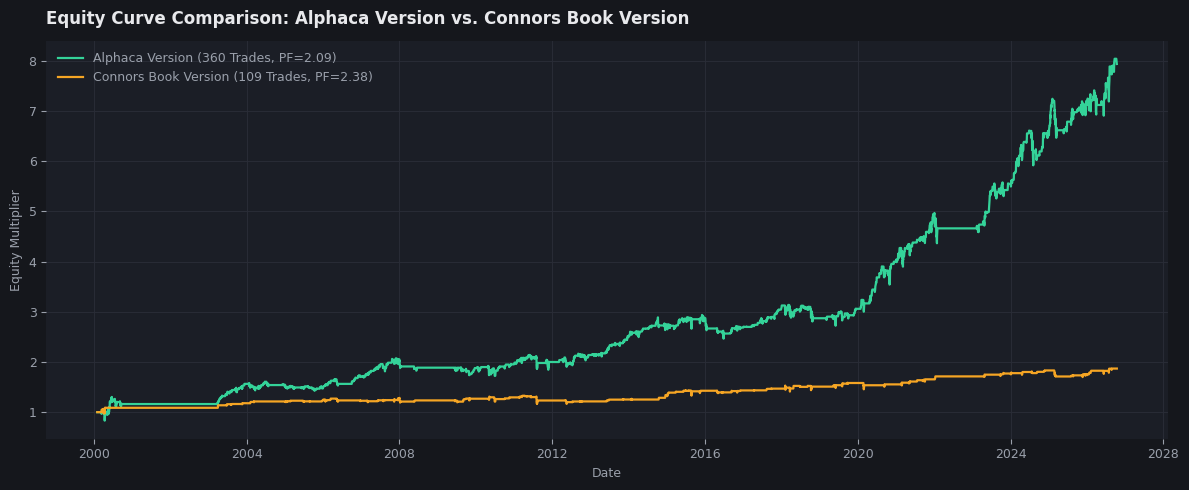

In [7]:
# Connors Original Book Rules: RSI(2) <= 5, Exit on Close > MA(5), Close > SMA(200)
df_connors = eng.prepare(df_raw, sma_len=200)
df_connors = df_connors[df_connors.index >= df.index[0]]
trades_connors = eng.run_rsi2_backtest(df_connors, rsi_thr=5.0, sma_len=200, exit_mode="ma5", slip_bps_per_side=SLIP_BPS)

m_tis = compute_metrics(trades_all, 1.0, 0.0)
m_con = compute_metrics(trades_connors, 1.0, 0.0)

ret_tis = eng.daily_returns(df, trades_all, "capital")
ret_con = eng.daily_returns(df_connors, trades_connors, "capital")
eq_tis = (1 + ret_tis).cumprod()
eq_con = (1 + ret_con).cumprod()

comp_variants = pd.DataFrame([
    {
        'Strategy Variant': f"Alphaca Version (RSI<{RSI_THR:g}, SMA={SMA_LEN}, 2 Green Candles Exit)",
        'Trades': m_tis['num_trades'],
        'Win Rate': f"{m_tis['win_rate']:.1f}%",
        'Profit Factor': f"{m_tis['profit_factor']:.3f}",
        'Expectancy': f"{m_tis['expectancy']:.3f}%",
        'Avg Holding (Bars)': f"{trades_all['bars'].mean():.1f}",
        'Sharpe': f"{sharpe_ratio(ret_tis):.2f}",
        'Max Drawdown': f"{max_drawdown(eq_tis)*100:.2f}%"
    },
    {
        'Strategy Variant': 'Connors Book Version (RSI<5, Close>MA5 Exit)',
        'Trades': m_con['num_trades'],
        'Win Rate': f"{m_con['win_rate']:.1f}%",
        'Profit Factor': f"{m_con['profit_factor']:.3f}",
        'Expectancy': f"{m_con['expectancy']:.3f}%",
        'Avg Holding (Bars)': f"{trades_connors['bars'].mean():.1f}",
        'Sharpe': f"{sharpe_ratio(ret_con):.2f}",
        'Max Drawdown': f"{max_drawdown(eq_con)*100:.2f}%"
    }
])

print("=" * 80)
print("VARIANT COMPARISON: Alphaca RULES VS. CONNORS BOOK RULES")
print("=" * 80)
display(comp_variants)

# Visual Comparison of Variants
fig, ax = plt.subplots(figsize=(12, 5), facecolor='#15171c')
ax.set_facecolor('#1b1e26')
ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(colors='#9aa0ab', labelsize=9)

ax.plot(df.index, eq_tis, color='#34d399', lw=1.6,
        label=f"Alphaca Version ({m_tis['num_trades']} Trades, PF={m_tis['profit_factor']:.2f})")
ax.plot(df_connors.index, eq_con, color='#f5a524', lw=1.6,
        label=f"Connors Book Version ({m_con['num_trades']} Trades, PF={m_con['profit_factor']:.2f})")
ax.set_title('Equity Curve Comparison: Alphaca Version vs. Connors Book Version', color='#e8e9ec', fontweight='bold', fontsize=12, loc='left', pad=12)
ax.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax.set_xlabel('Date', color='#9aa0ab', fontsize=9)
ax.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()

In [8]:
# Comparison: Baseline (15, 200) vs Configured (RSI_THR, SMA_LEN)
BASE_RSI, BASE_SMA = 15.0, 200

df_base_full = eng.prepare(df_raw, sma_len=BASE_SMA)
start = max(df.index[0], df_base_full.index[0])
d_cfg = df[df.index >= start]
d_base = df_base_full[df_base_full.index >= start]
assert d_cfg.index.equals(d_base.index), "Date index mismatch between comparison series."

t_cfg = eng.run_rsi2_backtest(d_cfg, rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)
t_base = eng.run_rsi2_backtest(d_base, rsi_thr=BASE_RSI, sma_len=BASE_SMA, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)

r_cfg = eng.daily_returns(d_cfg, t_cfg, sizing="atr")
r_base = eng.daily_returns(d_base, t_base, sizing="atr")
eq_cfg, eq_base = (1 + r_cfg).cumprod(), (1 + r_base).cumprod()

def _row(name, t, r, eq):
    m = compute_metrics(t, 1.0, 0.0)
    return {'Variant': name, 'Trades': m['num_trades'], 'Win Rate': f"{m['win_rate']:.1f}%",
            'Profit Factor': f"{m['profit_factor']:.3f}", 'Sharpe': f"{sharpe_ratio(r):.2f}",
            'Max Drawdown': f"{max_drawdown(eq)*100:.2f}%"}

print("=" * 80)
print(f"CONFIGURED ({RSI_THR:g}/{SMA_LEN}) vs BASELINE ({BASE_RSI:g}/{BASE_SMA})  |  common window: "
      f"{d_cfg.index[0]:%Y-%m-%d} to {d_cfg.index[-1]:%Y-%m-%d}  |  sizing ATR")
print("=" * 80)
display(pd.DataFrame([_row(f"Configured ({RSI_THR:g}/{SMA_LEN})", t_cfg, r_cfg, eq_cfg),
                      _row(f"Baseline ({BASE_RSI:g}/{BASE_SMA})", t_base, r_base, eq_base)]))

in_cfg, in_base = (r_cfg != 0), (r_base != 0)
print(f"Daily returns correlation             : {r_cfg.corr(r_base):.3f}")
print(f"Configured entries matching baseline  : {t_cfg['entry_time'].isin(t_base['entry_time']).mean():.0%}")
print(f"Baseline entries matching configured  : {t_base['entry_time'].isin(t_cfg['entry_time']).mean():.0%}")
print(f"Configured exits matching baseline    : {t_cfg['exit_time'].isin(t_base['exit_time']).mean():.0%}")
print(f"Days in position shared between both  : "
      f"{(in_cfg & in_base).sum() / max(in_cfg.sum(), 1):.0%}")

CONFIGURED (20/230) vs BASELINE (15/200)  |  common window: 2000-02-03 to 2026-10-13  |  sizing ATR


,Variant,Trades,Win Rate,Profit Factor,Sharpe,Max Drawdown
0,Configured (20/230),360,70.0%,2.094,0.74,-6.69%
1,Baseline (15/200),285,70.5%,2.105,0.65,-6.69%


Daily returns correlation             : 0.921
Configured entries matching baseline  : 60%
Baseline entries matching configured  : 75%
Configured exits matching baseline    : 78%
Days in position shared between both  : 80%


## 7. SUMMARY OF HYPOTHESIS & NEXT STEPS

In [9]:

m_all   = compute_metrics(trades_all, 1.0, 0.0)  
m_is    = compute_metrics(trades_is,  1.0, 0.0)
m_oos   = compute_metrics(trades_oos, 1.0, 0.0)

max_dd_atr = max_drawdown(eq_atr_all) * 100          
years      = (df.index[-1] - df.index[0]).days / 365.25

ticker  = TICKER
ATR_LEN, ATR_MULT, RISK_PCT = 14, 2, 1
next_nb = "02_RSI2_Optimization.ipynb"

confirmed = m_all["profit_factor"] > 1.5 and m_all["win_rate"] > 55
verdict   = "Hypothesis Confirmed" if confirmed else "Hypothesis NOT clearly confirmed"

if "is_reference" in globals() and is_reference and "tis_is" in globals():
    repro = (f"Our implementation vs Alphaca reference benchmark "
             f"({len(trades_is)} vs {tis_is['n']} IS trades, PF={m_is['profit_factor']:.3f} vs {tis_is['pf']:.3f}; "
             f"{len(trades_oos)} vs {tis_oos['n']} OOS trades, PF={m_oos['profit_factor']:.3f} vs {tis_oos['pf']:.3f}).")
else:
    repro = (f"Alphaca benchmark comparison not applicable (configured {RSI_THR:g}/{SMA_LEN} differs from reference 15/200). "
             f"Results here: {len(trades_is)} IS trades with PF={m_is['profit_factor']:.3f}; "
             f"{len(trades_oos)} OOS trades with PF={m_oos['profit_factor']:.3f}.")

print("=" * 80)
print("7. SUMMARY OF HYPOTHESIS & NEXT STEPS")
print("=" * 80)
print(f"""
Key Findings:

1. {verdict}: Buying short-term pullbacks (RSI(2) < {RSI_THR:g}) in an uptrend (Close > SMA({SMA_LEN})) yields {'a strong' if confirmed else 'a weak'} edge on {ticker} with a {m_all['win_rate']:.1f}% win rate and Profit Factor of {m_all['profit_factor']:.3f} across {years:.0f}+ years ({m_all['num_trades']} trades).

2. Robustness of ATR Sizing: The {RISK_PCT}% risk ATR({ATR_LEN})x{ATR_MULT} sizing model keeps maximum drawdown at {max_dd_atr:.2f}% over the entire {df.index[0].year}-{df.index[-1].year} span.

3. Reproducibility: {repro}

4. Next Step: Proceed to {next_nb} to evaluate parameter sensitivity and verify that (RSI(2) < {RSI_THR:g}, {SMA_LEN}) sits on a broad, stable parameter plateau on in-sample data.
""")

7. SUMMARY OF HYPOTHESIS & NEXT STEPS

Key Findings:

1. Hypothesis Confirmed: Buying short-term pullbacks (RSI(2) < 20) in an uptrend (Close > SMA(230)) yields a strong edge on QQQ with a 70.0% win rate and Profit Factor of 2.094 across 27+ years (360 trades).

2. Robustness of ATR Sizing: The 1% risk ATR(14)x2 sizing model keeps maximum drawdown at -6.69% over the entire 2000-2026 span.

3. Reproducibility: Alphaca benchmark comparison not applicable (configured 20/230 differs from reference 15/200). Results here: 237 IS trades with PF=1.867; 123 OOS trades with PF=2.592.

4. Next Step: Proceed to 02_RSI2_Optimization.ipynb to evaluate parameter sensitivity and verify that (RSI(2) < 20, 230) sits on a broad, stable parameter plateau on in-sample data.



In [10]:
# Save the results of this notebook for the variant
save_json(cfg, "01_hypothesis.json", {
    "variant": cfg["id"],
    "ticker": TICKER,
    "params": cfg["params"],
    "oos_start": str(oos_start.date()),
    "all": {"n": int(len(trades_all)), "pf": float(m_all["profit_factor"]), "win_rate": float(m_all["win_rate"])},
    "is":  {"n": int(len(trades_is)),  "pf": float(m_is["profit_factor"])},
    "oos": {"n": int(len(trades_oos)), "pf": float(m_oos["profit_factor"])},
    "max_dd_atr_pct": float(max_dd_atr),
    "hypothesis_confirmed": bool(confirmed),
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/RSI2/runs/v1_qqq/01_hypothesis.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/RSI2/runs/v1_qqq/01_hypothesis.json')